In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,accuracy_score, precision_score, recall_score, f1_score)

In [7]:
df = pd.read_csv("/bank_marketing_completo.csv")
print("dimensões:", df.shape)
df.head()

dimensões: (41188, 21)


,idade,profissao,estado_civil,escolaridade,inadimplente,financiamento_imobiliario,emprestimo_pessoal,meio_contato,mes,dia_semana,...,contatos_campanha_atual,dias_desde_ultimo_contato,contatos_anteriores,resultado_campanha_anterior,taxa_variacao_emprego,indice_precos_consumidor,indice_confianca_consumidor,euribor_3m,numero_empregados,aderiu
0,56,empregado_domestico,casado,fundamental_4anos,nao,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
1,57,servicos,casado,ensino_medio,desconhecido,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
2,37,servicos,casado,ensino_medio,nao,sim,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
3,40,administrativo,casado,fundamental_6anos,nao,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
4,56,servicos,casado,ensino_medio,nao,nao,sim,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao


In [9]:
df.info()
print("\nausentes:", df.isna().sum().sum())
df.describe().T[["min", "max", "mean"]]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   idade                        41188 non-null  int64  
 1   profissao                    41188 non-null  object 
 2   estado_civil                 41188 non-null  object 
 3   escolaridade                 41188 non-null  object 
 4   inadimplente                 41188 non-null  object 
 5   financiamento_imobiliario    41188 non-null  object 
 6   emprestimo_pessoal           41188 non-null  object 
 7   meio_contato                 41188 non-null  object 
 8   mes                          41188 non-null  object 
 9   dia_semana                   41188 non-null  object 
 10  duracao_ligacao_seg          41188 non-null  int64  
 11  contatos_campanha_atual      41188 non-null  int64  
 12  dias_desde_ultimo_contato    41188 non-null  int64  
 13  contatos_anterio

,min,max,mean
idade,17.000,98.000,40.024060
duracao_ligacao_seg,0.000,4918.000,258.285010
contatos_campanha_atual,1.000,56.000,2.567593
dias_desde_ultimo_contato,0.000,999.000,962.475454
contatos_anteriores,0.000,7.000,0.172963
taxa_variacao_emprego,-3.400,1.400,0.081886
indice_precos_consumidor,92.201,94.767,93.575664
indice_confianca_consumidor,-50.800,-26.900,-40.502600
euribor_3m,0.634,5.045,3.621291
numero_empregados,4963.600,5228.100,5167.035911


aderiu
nao    36548
sim     4640
Name: count, dtype: int64
aderiu
nao    88.734583
sim    11.265417
Name: proportion, dtype: float64


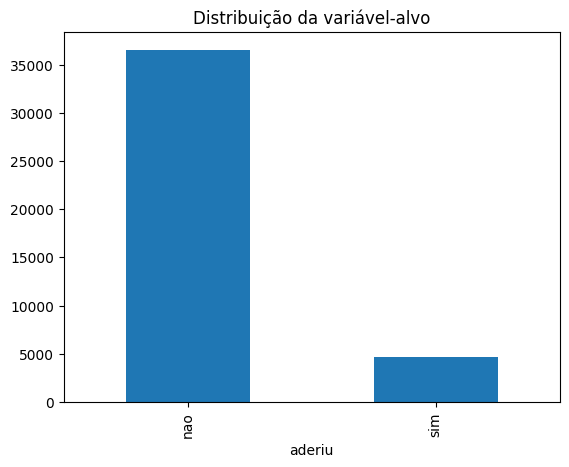

In [10]:
print(df["aderiu"].value_counts())
print(df["aderiu"].value_counts(normalize=True) * 100)
df["aderiu"].value_counts().plot(kind="bar")
plt.title("Distribuição da variável-alvo"); plt.show()

In [12]:
print("duplicadas:", df.duplicated().sum())
cat_cols = df.select_dtypes(exclude=[np.number]).columns.drop("aderiu")
print("\n'desconhecido' por coluna:")
print({c: int((df[c] == "desconhecido").sum()) for c in cat_cols if (df[c] == "desconhecido").any()})

print("\n% com dias_desde_ultimo_contato == 999:",
      round((df["dias_desde_ultimo_contato"] == 999).mean() * 100, 2))
print("\ninadimplente:\n", df["inadimplente"].value_counts())

duplicadas: 12

'desconhecido' por coluna:
{'profissao': 330, 'estado_civil': 80, 'escolaridade': 1731, 'inadimplente': 8597, 'financiamento_imobiliario': 990, 'emprestimo_pessoal': 990}

% com dias_desde_ultimo_contato == 999: 96.32

inadimplente:
 inadimplente
nao             32588
desconhecido     8597
sim                 3
Name: count, dtype: int64


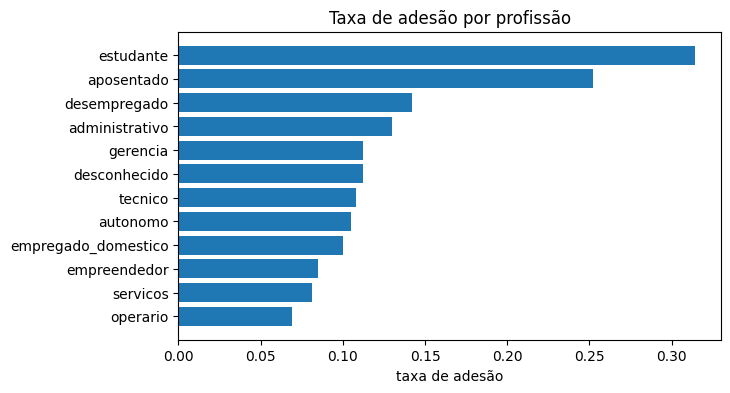

In [13]:
tmp = df.copy()
tmp["y"] = (tmp["aderiu"] == "sim").astype(int)
taxa = tmp.groupby("profissao")["y"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(taxa.index, taxa.values)
ax.set_title("Taxa de adesão por profissão"); ax.set_xlabel("taxa de adesão")
plt.show()

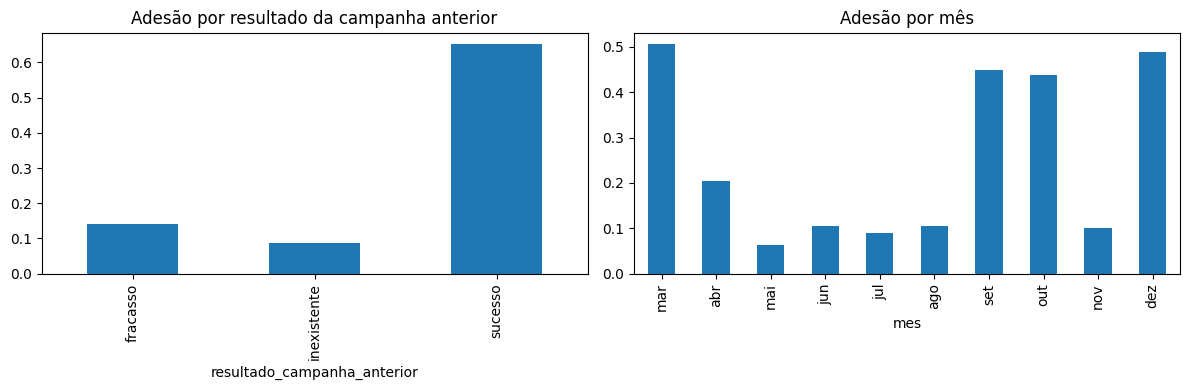

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
tmp.groupby("resultado_campanha_anterior")["y"].mean().plot(kind="bar", ax=eixos[0])
eixos[0].set_title("Adesão por resultado da campanha anterior")
ordem = ["mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
tmp.groupby("mes")["y"].mean().reindex(ordem).plot(kind="bar", ax=eixos[1])
eixos[1].set_title("Adesão por mês")
plt.tight_layout(); plt.show()

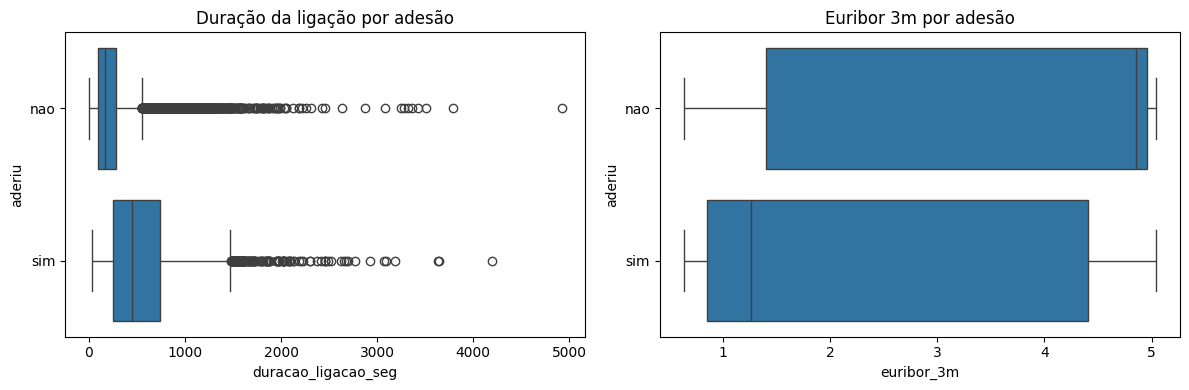

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="duracao_ligacao_seg", y="aderiu", ax=eixos[0])
eixos[0].set_title("Duração da ligação por adesão")
sns.boxplot(data=df, x="euribor_3m", y="aderiu", ax=eixos[1])
eixos[1].set_title("Euribor 3m por adesão")
plt.tight_layout(); plt.show()

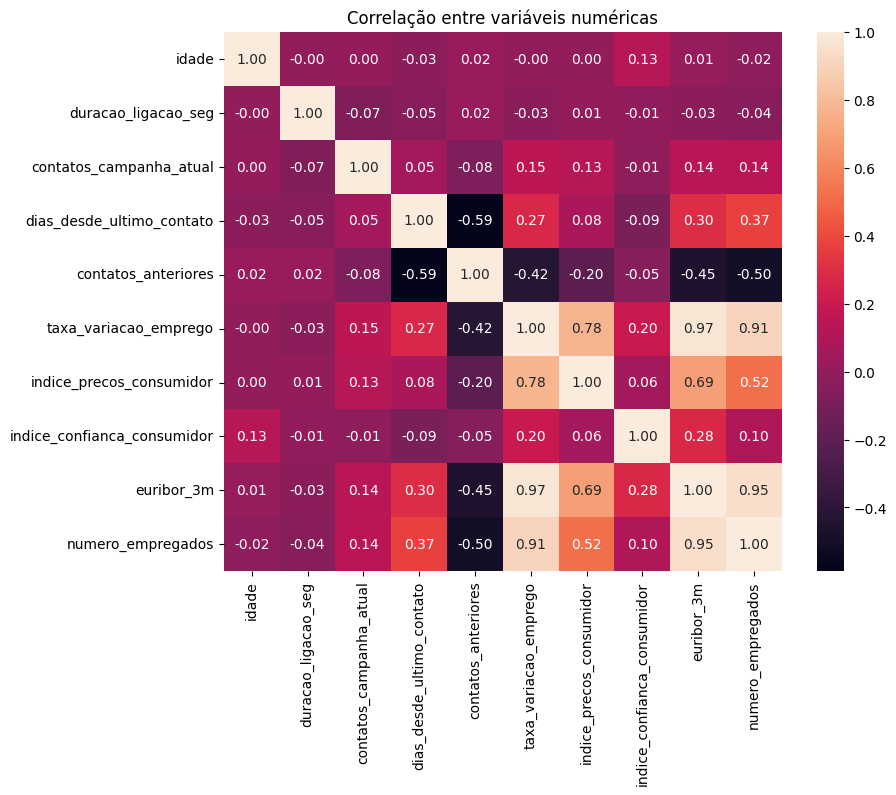

In [16]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f")
plt.title("Correlação entre variáveis numéricas"); plt.show()

In [17]:
d = df.copy()
antes = len(d)
d = d.drop_duplicates().reset_index(drop=True)
print("duplicadas removidas:", antes - len(d))
d["aderiu"] = (d["aderiu"] == "sim").astype(int)
d["foi_contatado_antes"] = (d["dias_desde_ultimo_contato"] != 999).astype(int)
d.loc[d["dias_desde_ultimo_contato"] == 999, "dias_desde_ultimo_contato"] = np.nan
print("dimensões:", d.shape)

duplicadas removidas: 12
dimensões: (41176, 22)


In [19]:
X = d.drop(columns="aderiu")
y = d["aderiu"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("treino:", X_treino.shape, "| teste:", X_teste.shape)
print("proporção de 'sim' -> treino:", round(y_treino.mean(), 4), "| teste:", round(y_teste.mean(), 4))

treino: (28823, 21) | teste: (12353, 21)
proporção de 'sim' -> treino: 0.1127 | teste: 0.1127


In [20]:
cols_excluidas = ["duracao_ligacao_seg", "contatos_campanha_atual"]
cols_completo = X_treino.columns.tolist()
cols_principal = [c for c in cols_completo if c not in cols_excluidas]
print("principal:", len(cols_principal), "atributos | completo:", len(cols_completo))

principal: 19 atributos | completo: 21


In [21]:
def montar_prep(cols):
    num = X_treino[cols].select_dtypes(include=[np.number]).columns.tolist()
    cat = X_treino[cols].select_dtypes(exclude=[np.number]).columns.tolist()
    pipe_num = Pipeline([("imputador", SimpleImputer(strategy="median")),
                         ("escala", StandardScaler())])
    pipe_cat = Pipeline([("imputador", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", pipe_num, num),
                              ("cat", pipe_cat, cat)])

In [22]:
X_busca, _, y_busca, _ = train_test_split(
    X_treino, y_treino, train_size=8000, random_state=42, stratify=y_treino)
print("amostra da busca:", X_busca.shape, "| proporção de 'sim':", round(y_busca.mean(), 4))

amostra da busca: (8000, 21) | proporção de 'sim': 0.1126


In [24]:
METRICA = "f1"
melhores = {}
for nome_cen, cols in [("principal", cols_principal), ("completo", cols_completo)]:
    pipe_knn = Pipeline([("prep", montar_prep(cols)),
                         ("knn", KNeighborsClassifier())])
    gs_knn = GridSearchCV(pipe_knn,
                          {"knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]},
                          cv=5, scoring=METRICA, n_jobs=-1)
    gs_knn.fit(X_busca[cols], y_busca)
    pipe_lr = Pipeline([("prep", montar_prep(cols)),
                        ("lr", LogisticRegression(max_iter=1000, random_state=42))])
    gs_lr = GridSearchCV(pipe_lr,
                         {"lr__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
                         cv=5, scoring=METRICA, n_jobs=-1)
    gs_lr.fit(X_busca[cols], y_busca)
    melhores[nome_cen] = {"k": gs_knn.best_params_["knn__n_neighbors"],
                          "C": gs_lr.best_params_["lr__C"]}
    print(f"[{nome_cen}] k = {melhores[nome_cen]['k']} (F1 CV = {gs_knn.best_score_:.4f}) | "
          f"C = {melhores[nome_cen]['C']} (F1 CV = {gs_lr.best_score_:.4f})")
    print("   F1 por C:", dict(zip([0.001, 0.01, 0.1, 1, 10, 100, 1000],
                                   gs_lr.cv_results_["mean_test_score"].round(3))))

[principal] k = 15 (F1 CV = 0.3542) | C = 1000 (F1 CV = 0.3510)
   F1 por C: {0.001: np.float64(0.239), 0.01: np.float64(0.319), 0.1: np.float64(0.334), 1: np.float64(0.345), 10: np.float64(0.347), 100: np.float64(0.349), 1000: np.float64(0.351)}
[completo] k = 3 (F1 CV = 0.4637) | C = 1000 (F1 CV = 0.5100)
   F1 por C: {0.001: np.float64(0.266), 0.01: np.float64(0.451), 0.1: np.float64(0.494), 1: np.float64(0.509), 10: np.float64(0.508), 100: np.float64(0.509), 1000: np.float64(0.51)}
